# 6.1更改模型为LSTM

## 环境依赖

In [8]:
import unicodedata
import string
import re
import random
import time
import math

import torch
import torch.nn as nn
from torch import optim
import torch.nn.functional as F

from sklearn.model_selection import train_test_split
from nltk.translate.bleu_score import SmoothingFunction,sentence_bleu
from tqdm import tqdm
from torch.utils.data import Dataset
import numpy as np
from torch.autograd import Variable
import jieba

如果使用GPU，则将下面的变量设为`True`。

In [9]:
USE_CUDA = True

## 读取数据

我们将读取目录下的`cn-eng.txt`文件，其中每一行是一个平行句对，例子如下：

```
我很冷。    I am cold.
```

### 对于单词进行编号

这里引入了两个特殊符号，“SOS”即“Start of sentence”和“EOS”即“End of sentence”。他们会加到输入文本的两端，以控制解码过程。

In [10]:
PAD_token = 0
SOS_token = 0
EOS_token = 1

class Lang:
    def __init__(self, name):
        self.name = name
        self.word2index = {}
        self.word2count = {}
        self.index2word = {0: "SOS", 1: "EOS"}
        self.n_words = 2 # Count SOS and EOS
      
    def index_words(self, sentence):
        # if self.name == 'cn':   
        #     for word in sentence:
        #         self.index_word(word)
        # else:
        #     for word in sentence.split(' '):
        #         self.index_word(word)
        
        # 中文jieba分词后，跟英文一样，句对都是按空格分离
        for word in sentence.split(' '):
            self.index_word(word)

    def index_word(self, word):
        if word not in self.word2index:
            self.word2index[word] = self.n_words
            self.word2count[word] = 1
            self.index2word[self.n_words] = word
            self.n_words += 1
        else:
            self.word2count[word] += 1

### 文本预处理

丢弃除了中文、字母和常用标点之外的符号。

In [11]:
# Turn a Unicode string to plain ASCII, thanks to http://stackoverflow.com/a/518232/2809427
def unicode_to_ascii(s):
    return ''.join(
        c for c in unicodedata.normalize('NFD', s)
        if unicodedata.category(c) != 'Mn'
    )

# Lowercase, trim, and remove non-letter characters
def normalize_string(s):
    s = unicode_to_ascii(s.lower().strip())
    s = re.sub(r"([.!?])", r" \1", s)
    # 保留英文引号和数字(全角数字０-９对应的unicode编码为\uff10-\uff19)
    # s = re.sub(r"[^a-zA-Z\u4e00-\u9fa5.!?，。？]+", r" ", s)
    s = re.sub(r"[^0-9\uff10-\uff19a-zA-Z\u4e00-\u9fa5'.!?，。？]+", r" ", s)
    return s

读取平行语料，并进行清理。

In [12]:
def read_langs(lang1, lang2, reverse=False):
    print("Reading lines...")

    # Read the file and split into lines
    lines = open('%s-%s.txt' % (lang1, lang2)).read().strip().split('\n')
    
    # 训练集和验证集按8:2分离     
    lines_train, lines_val = train_test_split(lines, test_size=0.2, random_state=10)

    # Split every line into pairs and normalize
    pairs_train = [[normalize_string(s) for s in l.split('\t')] for l in lines_train]
    pairs_val = [[normalize_string(s) for s in l.split('\t')] for l in lines_val]
    
    # Reverse pairs, make Lang instances
    if reverse:
        pairs = [list(reversed(p)) for p in pairs]
        input_lang = Lang(lang2)
        output_lang = Lang(lang1)
    else:
        input_lang = Lang(lang1)
        output_lang = Lang(lang2)
        
    return input_lang, output_lang, pairs_train, pairs_val

### 过滤句子

样例为了加快训练，只保留了不长于10个单词的句对，真正实验中将更多数据考虑进来可能获得更好的效果。

In [13]:
MAX_LENGTH = 40

def filter_pair(p):
    return len(p[1].split(' ')) < MAX_LENGTH

def filter_pairs(pairs):
    return [pair for pair in pairs if filter_pair(pair)]

处理数据的全过程：

- 读取数据，每一行分别处理，将其转换成句对
- 对于文本进行处理，过滤无用符号
- 根据已有文本对于单词进行编号，构建符号到编号的映射


In [14]:
def prepare_data(lang1_name, lang2_name, reverse=False):
        
    input_lang, output_lang, pairs_train, pairs_val = read_langs(lang1_name, lang2_name, reverse)
    print("Read %s sentence pairs for train" % len(pairs_train))
    pairs_train = filter_pairs(pairs_train)
    print("Trimmed to %s sentence pairs for train" % len(pairs_train))
    print("Read %s sentence pairs for validate" % len(pairs_val))
    pairs_val = filter_pairs(pairs_val)
    print("Trimmed to %s sentence pairs for validate" % len(pairs_val))

    print("Indexing words...")
    for pair in pairs_train:
        # 对中文进行Jieba分词
        pair[0] =' '.join(jieba.cut(pair[0]))
        input_lang.index_words(pair[0])
        output_lang.index_words(pair[1])
    for pair in pairs_val:
        # 对中文进行Jieba分词
        pair[0] =' '.join(jieba.cut(pair[0]))
        input_lang.index_words(pair[0])
        output_lang.index_words(pair[1])

    return input_lang, output_lang, pairs_train, pairs_val

# 训练集:pairs_train; 验证集:pairs_val
input_lang, output_lang, pairs_train, pairs_val = prepare_data('cn', 'eng', False)

# 随机打印一条训练集和验证集的句对
print(random.choice(pairs_train))
print(random.choice(pairs_val))

Reading lines...


Building prefix dict from the default dictionary ...
Loading model from cache /tmp/jieba.cache


Read 72000 sentence pairs for train
Trimmed to 71907 sentence pairs for train
Read 18000 sentence pairs for validate
Trimmed to 17980 sentence pairs for validate
Indexing words...


Loading model cost 0.459 seconds.
Prefix dict has been built successfully.


['第二 學期 結束 了 。', 'second semester has ended .']
['你 很早 起床 ， 不是 嗎   ?', "you get up early don't you ?"]


## 将文本数据转换为张量

为了训练，我们需要将句子变成神经网络可以理解的东西（数字）。每个句子将被分解成单词，然后变成张量，其中每个单词都被索引替换（来自之前的Lang索引）。在创建这些张量时，我们还将附加EOS令牌以表示该句子已结束。

![](https://i.imgur.com/LzocpGH.png)

In [15]:
# Return a list of indexes, one for each word in the sentence
def indexes_from_sentence(lang, sentence):
    # if lang.name == 'cn':
    #     return [lang.word2index[word] for word in sentence]
    # else:
    #     return [lang.word2index[word] for word in sentence.split(' ')]

    # jieba中文分词
    # if lang.name == 'cn':
    #     # sentence = jieba.lcut(sentence)
    #     return [lang.word2index[word] for word in sentence]
    # else:
    print(sentence)
    return [lang.word2index[word] for word in sentence.split(' ')]

def variable_from_sentence(lang, sentence):
    indexes = indexes_from_sentence(lang, sentence)
    indexes.append(EOS_token)
    # var = torch.LongTensor(indexes).view(-1, 1)
    # if USE_CUDA: 
    #     var = var.cuda()
    # return var
    return indexes

def variables_from_pair(pair):
    input_variable = variable_from_sentence(input_lang, pair[0])
    target_variable = variable_from_sentence(output_lang, pair[1])
    return (input_variable, target_variable)

### 批处理

In [16]:
class Seq2eq_dataset(Dataset):
    def __init__(self, pairs):
        self.input_variable_list = []
        self.target_variable_list = []
        for pair in pairs:
            i,t =variables_from_pair(pair)
            self.input_variable_list.append(i)
            self.target_variable_list.append(t)

    def __len__(self):
        return len(self.input_variable_list)
        
    def __getitem__(self, i):
        input_variable = self.input_variable_list[i]
        target_variable = self.target_variable_list[i]
        return input_variable, target_variable, len(input_variable), len(target_variable)


In [17]:
def seq2eq_collate_func(batch):
    input_variable_list = []
    target_variable_list = []
    input_len_list = []
    target_len_list = []

    # 取批内最大长度
    for d in batch: 
        input_len_list.append(d[2])
        target_len_list.append(d[3])    
    max_len_src = max(input_len_list)
    max_len_trg = max(target_len_list)
    
    for d in batch:     
         
        # 源语句处理：按右填充
        padded_source = np.pad(np.array(d[0]), 
                                pad_width=((0,max_len_src-d[2])),          
                                mode="constant", constant_values=PAD_token)

        input_variable_list.append(padded_source)
        
        # 目标语句处理：按右填充
        padded_target = np.pad(np.array(d[1]), 
                                pad_width=((0,max_len_trg-d[3])),     
                                mode="constant", constant_values=PAD_token)
        target_variable_list.append(padded_target)
        
    #批内数据排序
    sort_idx = sorted(range(len(input_len_list)), key=input_len_list.__getitem__, reverse=True)
    input_variable_list = np.array(input_variable_list)[sort_idx]
    target_variable_list = np.array(target_variable_list)[sort_idx]
    input_len_list = np.array(input_len_list)[sort_idx]
    target_len_list = np.array(target_len_list)[sort_idx]


    # if USE_CUDA: 
    #     return [torch.tensor(input_variable_list).cuda(), 
    #             torch.tensor(target_variable_list).cuda(), 
    #             torch.LongTensor(input_len_list), 
    #             torch.LongTensor(target_len_list)] 

    return [torch.from_numpy(input_variable_list),torch.from_numpy(target_variable_list),torch.from_numpy(input_len_list),torch.from_numpy(target_len_list)]

In [18]:
batch_size = 4
num_workers = 16
train_loader = torch.utils.data.DataLoader(Seq2eq_dataset(pairs_train),
                                           collate_fn = seq2eq_collate_func,
                                           batch_size = batch_size, 
                                           shuffle=True, 
                                           num_workers=num_workers)
val_loader = torch.utils.data.DataLoader(Seq2eq_dataset(pairs_val),
                                           collate_fn = seq2eq_collate_func,
                                           batch_size = batch_size, 
                                           shuffle=True, 
                                           num_workers=num_workers)


她 也 学习 汉语 。
she learns chinese too .
我累 得 只 想 躺 在 床上 。
i was too tired to care for anything but bed .
我 在 信封 上 写错 了 地址 。
i wrote the wrong address on the envelope .
我们 去 看 电影吧  
let's go to the movies .
他 還沒有 真正 去 過美國 。
he hasn't actually been to america .
比起 少 抽 菸 ， 你 何不 直接 把 菸 戒 了 ？
rather than cutting down on cigarettes why don't you just give them up ?
在 英国 的 时候 ， 我 经常 看 参考书 。
while in england i often consulted the guidebook .
花子 又 忘記 她 的 傘 了 。
hanako has forgotten her umbrella again .
这是 火车站 吗 ？
is that the railroad station ?
他 偶爾會 來 看 我們 。
he comes to visit us every now and then .
別放棄 我   !
don't abandon me !
我 知道 你 盡力 了 。
i know that you did your best .
離開 這裡 。
get out of here .
今天 下 这么 大 的 雨 ， 土松 着 呢 。
it is still raining a lot today and the soil is being broken up .
你 最好 馬 上去 做 。
you had better do it at once .
他們 也 不能 聽見 我 說 話 。
they can't hear me either .
你 父母 親 在家 嗎 ？
were your mother and father home ?
今天 是 个 好日子 。
today is a good day .
我 不 喜欢 那家伙 。
i don't like that guy .
有

In [19]:
pairs_train[:5]

[['她 也 学习 汉语 。', 'she learns chinese too .'],
 ['我累 得 只 想 躺 在 床上 。', 'i was too tired to care for anything but bed .'],
 ['我 在 信封 上 写错 了 地址 。', 'i wrote the wrong address on the envelope .'],
 ['我们 去 看 电影吧  ', "let's go to the movies ."],
 ['他 還沒有 真正 去 過美國 。', "he hasn't actually been to america ."]]

# 组件模型

## 编码器

In [20]:
class EncoderLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, n_layers=1):
        super(EncoderLSTM, self).__init__()
        
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.n_layers = n_layers
        
        self.embedding = nn.Embedding(input_size, hidden_size)
        self.lstm = nn.LSTM(hidden_size, hidden_size, n_layers)
      
   
    def forward(self, word_inputs, input_lengths, hidden):
        # 在多个批次的多个序列上一次执行所有操作
        embedded = self.embedding(word_inputs)
        # 对填充过的数据进行压缩
        packed = torch.nn.utils.rnn.pack_padded_sequence(embedded, input_lengths)
        outputs, hidden = self.lstm(packed, hidden)
        # 解压，返回填充
        outputs, output_lengths = torch.nn.utils.rnn.pad_packed_sequence(outputs)
        # 构造输出数据（shape为[seq_len, batch_size,hidden_size]）
        
        outputs = outputs[:, :, :]

        return outputs, hidden, output_lengths

    def init_hidden(self,batch_size):
        # 初始化隐藏状态和单元状态
        hidden = torch.zeros(self.n_layers, batch_size, self.hidden_size)
        cell = torch.zeros(self.n_layers, batch_size, self.hidden_size)
        if USE_CUDA: 
            hidden = hidden.cuda()
            cell = cell.cuda()
        return (hidden, cell)

## 解码器

In [21]:
class DecoderLSTM(nn.Module):
    def __init__(self, hidden_size, output_size, n_layers=1, dropout_p=0.1):
        super(DecoderLSTM, self).__init__()
        
        # Keep parameters for reference
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.n_layers = n_layers
        
        # Define layers
        self.embedding = nn.Embedding(output_size, hidden_size, padding_idx=PAD_token)
        self.lstm = nn.LSTM(hidden_size, hidden_size, n_layers, dropout=dropout_p)
        self.out = nn.Linear(hidden_size, output_size)
        self.dropout = nn.Dropout(dropout_p)
   
    def forward(self, word_input, last_hidden, batch_size):
        # Note: we run this one step at a time        
        word_embedded = self.embedding(word_input).view(1, batch_size, -1) 
        word_embedded = self.dropout(word_embedded)
        output = F.relu(word_embedded)
        lstm_output, hidden = self.lstm(word_embedded, last_hidden)

        lstm_output = lstm_output.squeeze(0)
        output = F.log_softmax(self.out(lstm_output), dim=1)

        return output, hidden

# 训练

## 一次训练迭代

为了训练，我们首先通过编码器逐字运行输入语句，并跟踪每个输出和最新的隐藏状态。接下来，为解码器提供解码器的最后一个隐藏状态作为其第一隐藏状态，并向其提供`<SOS>`作为其第一输入。从那里开始，我们迭代地预测来自解码器的下一个单词。
    
### Teacher Forcing 和 Scheduled Sampling

"Teacher Forcing"指的是每次都基于完全准确的上文进行解码，这样训练模型收敛很快，但是会造成实际场景和训练场景有较大差别，因为实际场景上文也都是模型预测的，可能不准确，具体细节可参考[论文](http://minds.jacobs-university.de/sites/default/files/uploads/papers/ESNTutorialRev.pdf)。

观察Teacher Forcing的网络的输出，我们可以看到该网络语法连贯，但是偏离正确的翻译。可以将其为学会了如何听老师的指示，而未学习如何独自冒险。

解决强迫教师问题的方法称为“计划抽样”（[Scheduled Sampling](https://arxiv.org/abs/1506.03099)），它在训练时仅在使用目标值和预测值之间进行切换。我们将在训练时随机选择,有时我们将使用真实目标作为输入（忽略解码器的输出），有时我们将使用解码器的输出。

In [22]:
def sequence_mask(sequence_length, max_len=None):
    """     
    代码参考来源：https://github.com/spro/practical-pytorch/blob/master/seq2seq-translation/masked_cross_entropy.py
    """
    if max_len is None:
        max_len = sequence_length.data.max()
    batch_size = sequence_length.size(0)
    seq_range = torch.arange(0, max_len).long()
    seq_range_expand = seq_range.unsqueeze(0).expand(batch_size, max_len).contiguous()
    if USE_CUDA:
        seq_range_expand = seq_range_expand.cuda()
    seq_length_expand = (sequence_length.unsqueeze(1)
                         .expand_as(seq_range_expand))
    return seq_range_expand < seq_length_expand



def masked_cross_entropy(logits, target, length):
    length = torch.LongTensor(length)

    if USE_CUDA:
        length = length.cuda()
    """
    代码参考来源：https://github.com/spro/practical-pytorch/blob/master/seq2seq-translation/masked_cross_entropy.py
    """  

    # logits_flat: (batch * max_len, num_classes)
    logits_flat = logits.view(-1, logits.size(-1))
    # log_probs_flat: (batch * max_len, num_classes)
    log_probs_flat = F.log_softmax(logits_flat, dim=1)
    # target_flat: (batch * max_len, 1)
    target_flat = target.view(-1, 1)
    # losses_flat: (batch * max_len, 1)
    losses_flat = -torch.gather(log_probs_flat, dim=1, index=target_flat)
    # losses: (batch, max_len)
    losses = losses_flat.view(*target.size())
    # mask: (batch, max_len)
    mask = sequence_mask(sequence_length=length, max_len=target.size(1))
    losses = losses * mask.float()
    loss = losses.sum() / length.float().sum()
    return loss

In [23]:
def train(input_tensor, target_tensor, input_lengths, target_lengths, encoder, decoder, 
          encoder_optimizer, decoder_optimizer, teacher_forcing_ratio, clip=10.0):
    decoder.train()
    encoder.train()
    
    
    batch_size = input_tensor.size(1)
    if USE_CUDA:
        input_tensor = input_tensor.cuda()
        target_tensor = target_tensor.cuda()
        
    # Run words through encoder
    encoder_hidden = encoder.init_hidden(batch_size)
    encoder_outputs, encoder_hidden, encoder_output_lengths = encoder(input_tensor, input_lengths,encoder_hidden)


    # Prepare input and output variables
    decoder_input = torch.tensor([SOS_token]*batch_size)  # decoder_input: torch.Size([1, 32])
    decoder_hidden = encoder_hidden[:decoder.n_layers] 
    # Use last (forward) hidden state from encoder
    all_decoder_outputs = Variable(torch.zeros(target_lengths.max(), batch_size, decoder.output_size))
    if USE_CUDA:
        decoder_input = decoder_input.cuda()
        all_decoder_outputs = all_decoder_outputs.cuda()
    
    # Added onto for each word
    loss = 0 

    # Choose whether to use teacher forcing
    use_teacher_forcing = random.random() < teacher_forcing_ratio
    
    if use_teacher_forcing:
        # Teacher forcing: Feed the target as the next input
        for di in range(target_lengths.max()):
            decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden, batch_size)
            
            decoder_input = target_tensor[di]  # Teacher forcing
            all_decoder_outputs[di] = decoder_output
            
    else:
        # Without teacher forcing: use its own predictions as the next input
        for di in range(target_lengths.max()):
            decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden, batch_size)
            
            topv, topi = decoder_output.topk(1)

            decoder_input = topi.squeeze().detach()  # detach from history as input
            all_decoder_outputs[di] = decoder_output
           

    # zero out the accumulated gradient over mini-batch
    encoder_optimizer.zero_grad()  
    decoder_optimizer.zero_grad()

    # Loss calculation and backpropagation

    loss = masked_cross_entropy(
        all_decoder_outputs.transpose(0, 1).contiguous(), # -> batch x seq
        target_tensor.transpose(0, 1).contiguous(), # -> batch x seq
        target_lengths
    )
    
    # loss = loss.sum()/batch_size 
    loss.backward()
    # ave_loss.backward()
    
    # Clip gradient norms
    torch.nn.utils.clip_grad_norm_(encoder.parameters(), clip)
    torch.nn.utils.clip_grad_norm_(decoder.parameters(), clip)
    
    encoder_optimizer.step()   # update parameters
    decoder_optimizer.step()

    return loss.item()
     

### 验证方法

In [24]:
def get_batch_outputs(encoder, decoder, input_sentences, input_lengths, output_lengths): 
    with torch.no_grad():
        input_tensor = input_sentences.transpose(0,1)
        if USE_CUDA:
            input_tensor = input_tensor.cuda()
        batch_size = input_tensor.size(1)
        encoder_hidden = encoder.init_hidden(batch_size)
        encoder_outputs, encoder_hidden,encoder_output_lengths = encoder(input_tensor, input_lengths, encoder_hidden)
          
        decoder_hidden = encoder_hidden[:decoder.n_layers]

        decoder_input = Variable(torch.tensor([SOS_token]*batch_size))
        if USE_CUDA:
            decoder_input = decoder_input.cuda()
        decoded_words = np.empty((output_lengths.max(), batch_size), dtype=object)

        for di in range(output_lengths.max()):
            decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden, batch_size)

            topv, topi = decoder_output.topk(1)
            decoder_input = topi.flatten().detach() 
            if USE_CUDA:
                decoder_input = decoder_input.cuda()

            decoded_words[di:] = np.array(['' if idx==EOS_token else output_lang.index2word[idx] for idx in decoder_input.tolist()])

        # print(decoded_words.transpose())
        return decoded_words.transpose()

def evaluate(encoder, decoder, loader):
  
    """
    Thanks for the sacrebleu.py in 
    github https://github.com/mjpost/sacreBLEU/blob/master/sacrebleu.py#L1022-L1080
    """
    
    encoder.eval()
    decoder.eval()
    
    score = []
    src_sentences = []
    sys_sentences = []
    ref_sentences = []
    encoder.train(False)
    decoder.train(False)
    for i, (input_sentences, target_sentences, input_len, target_len) in enumerate(loader):
        # print(target_sentences)
        for sentence in target_sentences:
            # print(sentence)
            trg_list = []
            for idx in sentence:
                if idx.item() == EOS_token:
                    break
                else:
                    trg_list.append(output_lang.index2word[idx.item()])
            ref_sentences.append(' '.join(trg_list))
        for sentence in input_sentences:
            src_list = []
            for idx in sentence:
                if idx.item() == EOS_token:
                    break
                else:
                    src_list.append(input_lang.index2word[idx.item()])
            src_sentences.append(' '.join(src_list))

        # ref_sentences.append(' '.join(sent) for sent in target_sentences)
        #src_sentences.append(' '.join(sent) for sent in input_sentences)
        batch_size = input_sentences.size(0)
        batch_outputs = get_batch_outputs(encoder, decoder, input_sentences, input_len, target_len)
        for sentence in batch_outputs:
            try:
                end_idx = sentence.tolist().index('')
                sys_sentences.append(' '.join(sentence[:end_idx]))
            except ValueError:
                sys_sentences.append(' '.join(sentence))
            
    encoder.train(True)
    decoder.train(True) 
    
    
    # score = corpus_bleu(sys_sentences,[ref_sentences], smooth="floor", smooth_floor=0.01, lowercase=False, use_effective_order=True, tokenize=DEFAULT_TOKENIZER).score
    # return score, (src_sentences[0:1], sys_sentences[0:1], ref_sentences[0:1])
    # return src_sentences[0:1], sys_sentences[0:1], ref_sentences[0:1]
    return src_sentences, sys_sentences, ref_sentences

### 辅助输出训练情况的函数

In [25]:
def as_minutes(s):
    m = math.floor(s / 60)
    s -= m * 60
    return '%dm %ds' % (m, s)

def time_since(since, percent):
    now = time.time()
    s = now - since
    es = s / (percent)
    rs = es - s
    return '%s (- %s)' % (as_minutes(s), as_minutes(rs))

In [26]:
def trainIters(encoder, decoder, epochs, encoder_optimizer, decoder_optimizer, teacher_forcing_ratio,
               print_every=10, plot_every=1000, evaluate_every=3000):
    start = time.time()


    score_max = 0
    plot_losses = []
    validation_score = []
    
    for epoch in range(1, epochs + 1):
        with tqdm(total=len(train_loader), desc=f"[Epoch {epoch:3d}/{epochs}]") as pbar:
            print_loss_total = 0  # Reset every print_every
            plot_loss_total = 0  # Reset every plot_every
            
            for i, (input_variable, target_variable,input_len,target_len) in enumerate(train_loader): 
                encoder.train()
                decoder.train()
                
                input_tensor = input_variable.transpose(0,1)   
                target_tensor = target_variable.transpose(0,1)
                loss = train(input_tensor, target_tensor, input_len, target_len, 
                             encoder, decoder, encoder_optimizer, decoder_optimizer, teacher_forcing_ratio)
                print_loss_total += loss
                plot_loss_total += loss
    
                        
                if i > 0 and i % print_every == 0:
                    print_loss_avg = print_loss_total / print_every
                    print_loss_total = 0

                    pbar.set_postfix({'Train Loss': '[{:4f}(avg. {:4f})]'.format(loss,print_loss_avg)})
                    pbar.update(print_every)
                    
                if i > 0 and i % plot_every == 0:
                    plot_loss_avg = plot_loss_total / plot_every
                    plot_losses.append(plot_loss_avg)
                    plot_loss_total = 0
                torch.cuda.empty_cache()    
            # print("plot_losses:",plot_losses)
            # print("validation_scores:",validation_scores)
        
        # 计算epoch的BLEU
        src_sentences, sys_sentences, ref_sentences = evaluate(encoder, decoder, val_loader)
        bleu_scores = list() 
        for i in range(len(src_sentences)):
            bleu_score = sentence_bleu([ref_sentences[i].split()], sys_sentences[i].split(), smoothing_function= SmoothingFunction().method4)
            bleu_scores.append(bleu_score)
        bleu_scores_epoch = np.average(bleu_scores)

        # 如果是历史新高，保存模型
        if len(validation_score)==0 or bleu_scores_epoch > np.max(validation_score):
            state = {'epoch': epoch,
                'bleu': bleu_scores_epoch,
                'encoder': encoder,
                'decoder': decoder,
                'encoder_optimizer': encoder_optimizer,
                'decoder_optimizer': decoder_optimizer}
            torch.save(state, './output/lstm.pth.tar')
        validation_score.append(np.average(bleu_scores))
    return plot_losses, validation_score

## 进行训练

以下设置变量用于绘制图标和跟踪进度：

In [27]:
# Configuring training
n_epochs = 8
# plot_every = 1
print_every = 10
plot_losses = []

# Keep track of time elapsed and running averages
# start = time.time()
# plot_losses = []
# print_loss_total = 0 # Reset every print_every
# plot_loss_total = 0 # Reset every plot_every

hidden_size = 500
n_layers = 2
dropout_p = 0.05
teacher_forcing_ratio = 0.5
clip = 5.0

# Initialize models
encoder = EncoderLSTM(input_lang.n_words, hidden_size, n_layers)
decoder = DecoderLSTM(hidden_size, output_lang.n_words, n_layers, dropout_p=dropout_p)

# Move models to GPU
if USE_CUDA:
    encoder.cuda()
    decoder.cuda()

# Initialize optimizers and criterion
learning_rate = 0.0001
encoder_optimizer = optim.Adam(encoder.parameters(), lr=learning_rate)
decoder_optimizer = optim.Adam(decoder.parameters(), lr=learning_rate)
criterion = nn.NLLLoss()


要进行实际训练，我们会多次调用训练函数，并在进行过程中打印中间信息。

In [28]:
plot_losses, validation_scores = trainIters(encoder, decoder, n_epochs, encoder_optimizer, decoder_optimizer, teacher_forcing_ratio, print_every=print_every)

[Epoch   8/8]: 100%|█████████▉| 17970/17977 [18:39<00:00, 16.05it/s, Train Loss=[0.953578(avg. 1.290611)]]


## loss 和bleu可视化

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


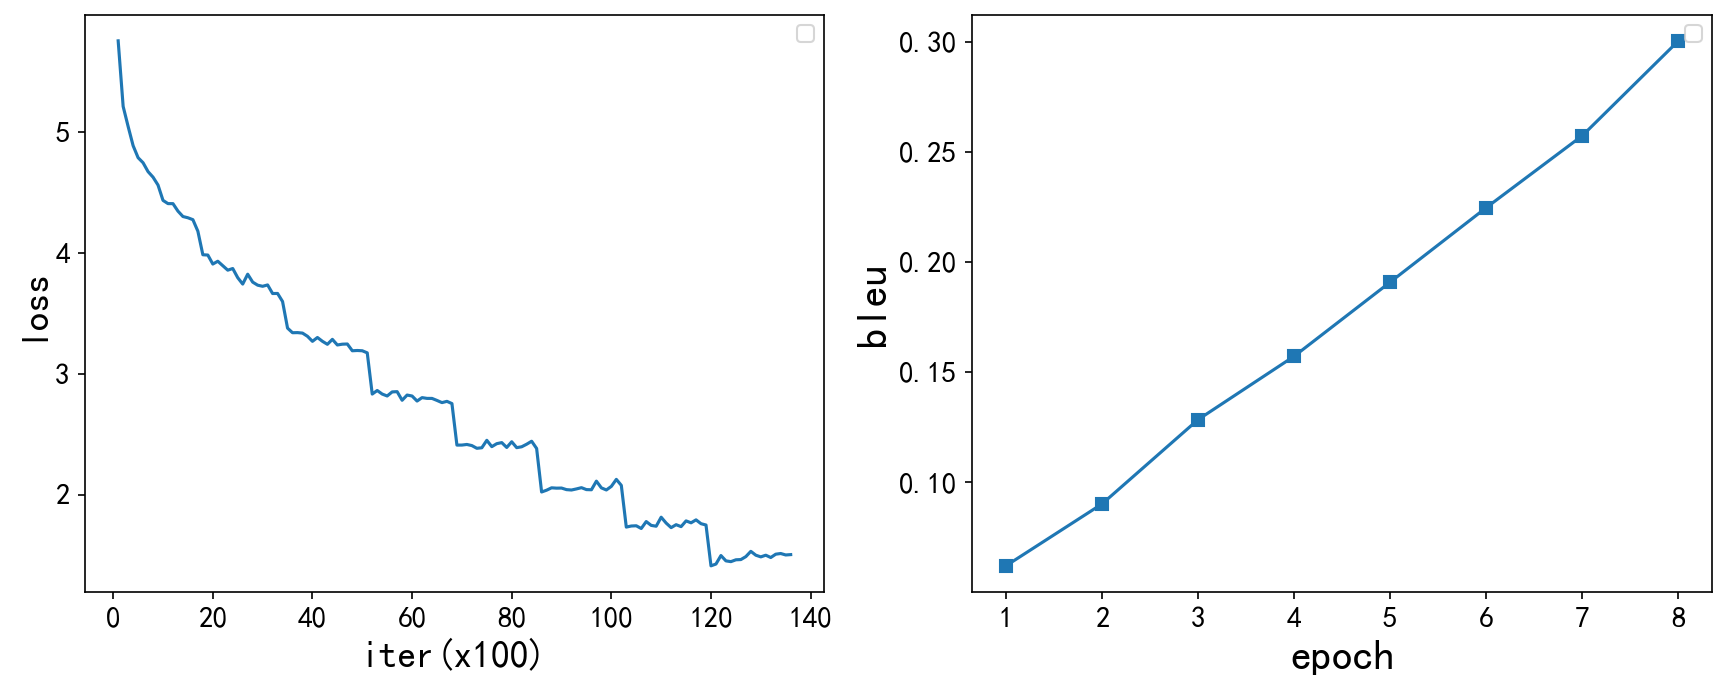

In [29]:
import matplotlib.pyplot as plt

# plt.figure()
# fig, ax = plt.subplots()
# loc = ticker.MultipleLocator(base=0.2) # put ticks at regular intervals
# ax.yaxis.set_major_locator(loc)
# plt.plot(plot_losses)



plt.figure(figsize=(14,5), dpi=150)
plt.rcParams['font.sans-serif']=['SimHei']
plt.subplot(121)
plt.plot(range(1,len(plot_losses)+1), plot_losses)
plt.xlabel('iter(x100)', fontsize=18, fontweight='bold')
plt.ylabel('loss', fontsize=18, fontweight='bold')
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend()
plt.subplot(122)
plt.plot(range(1,len(validation_scores)+1), validation_scores, marker='s')
plt.xlabel('epoch', fontsize=20, fontweight='bold')
plt.ylabel('bleu', fontsize=20, fontweight='bold')
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend()
plt.show()

In [30]:
plot_losses

[5.753082862377167,
 5.210460604906082,
 5.044639014005661,
 4.8860473623275755,
 4.786486106395722,
 4.744543328762054,
 4.671094172000885,
 4.625362683534622,
 4.560023060560226,
 4.433350912809372,
 4.406626857757568,
 4.406347616910934,
 4.344546309709549,
 4.299852181196213,
 4.289546005964279,
 4.273772156715393,
 4.178129354715347,
 3.9835259970426558,
 3.9812119545936584,
 3.9067880215644837,
 3.9300076916217805,
 3.8928927826881408,
 3.8561520980596544,
 3.8697519998550414,
 3.793979071378708,
 3.7410602585077286,
 3.8228243713378904,
 3.7573775668144225,
 3.7320427072048186,
 3.722796740055084,
 3.733995117068291,
 3.6629152584075926,
 3.6635605462789536,
 3.5968128439188005,
 3.3768713001012802,
 3.338674482822418,
 3.339673179268837,
 3.335616690158844,
 3.3092544342279435,
 3.267424507856369,
 3.2992366120815277,
 3.267820188522339,
 3.242873596549034,
 3.2838008724451067,
 3.2373985668420793,
 3.2439078606367113,
 3.2454834039211273,
 3.1895221602916717,
 3.19170350217819

In [31]:
np.max(validation_scores)

0.3003445742649686

# 模型验证

In [32]:
model = torch.load('./output/lstm.pth.tar')
encoder_val = model['encoder']
decoder_val = model['decoder']
src_sentences, sys_sentences, ref_sentences = evaluate(encoder_val, decoder_val, val_loader)

### 取约定的数据进行验证

In [33]:

val_man = ['美國在一八六三年廢除了奴隸制度。',
            '关门。',
            '我不喝水。',
            '请安装linux!',
            '为什么我还在这里？',
            '這本書有一個弱點作者自己結了婚，但卻建議別人不要結婚，沒有甚麼說服力。']

pairs_man= []
for i in range(len(src_sentences)):
    # print('>', src_sentences[i])
    input_cn = src_sentences[i].replace(' ','')
    if input_cn in val_man and input_cn not in pairs_man:          
        pairs_man.append(input_cn) 
        
        print('>', input_cn)
        print('=', ref_sentences[i])
        print('<', sys_sentences[i])
        print('')

> 這本書有一個弱點作者自己結了婚，但卻建議別人不要結婚，沒有甚麼說服力。
= the weak point of this book is that it's less than persuasive when the married author recommends not being married .
< this movie is strange in that even even even even it has even even if it is not . .

> 请安装linux!
= install linux !
< please ! !

> 关门。
= close the door .
< shut the door .

> 为什么我还在这里？
= why am i still here ?
< why are still still here ?

> 美國在一八六三年廢除了奴隸制度。
= america did away with slavery in 1863 .
< america did away with the slavery .

> 我不喝水。
= i don't drink water .
< i don't drink water .

